# Step 4. Apply

*With ngff-zarr.*

**Goal:** use the registration straight from the scene, without writing a resampled copy. `pair.ozx` is enough: the
two images and the transformation travel together.

In [ ]:
import ngff_zarr as nz
from common import DATA, dice, ncc, scene_fields, show

SCENE = "../output/pair.ozx"
scene = nz.NgffScene.from_ome_zarr(SCENE)
T = scene.coordinateTransformations[0]
fixed, moving = scene.images["fixed"].images[0], scene.images["moving"].images[0]
moved = nz.resample(T, fixed, moving, fields=scene_fields(SCENE, T))  # lazy: described block by block, nothing read yet
moved.data

dask.array<ngff-zarr-resample, shape=(50, 680, 535), dtype=uint16, chunksize=(50, 128, 128), chunktype=numpy.ndarray>

`moved` is the moving image drawn on the fixed grid: for each voxel $x$ of the fixed image, the moving image read at
$T(x)$. Computing one plane reads only the part of the moving image that plane needs. Where the two rounds agree,
green and magenta turn white:

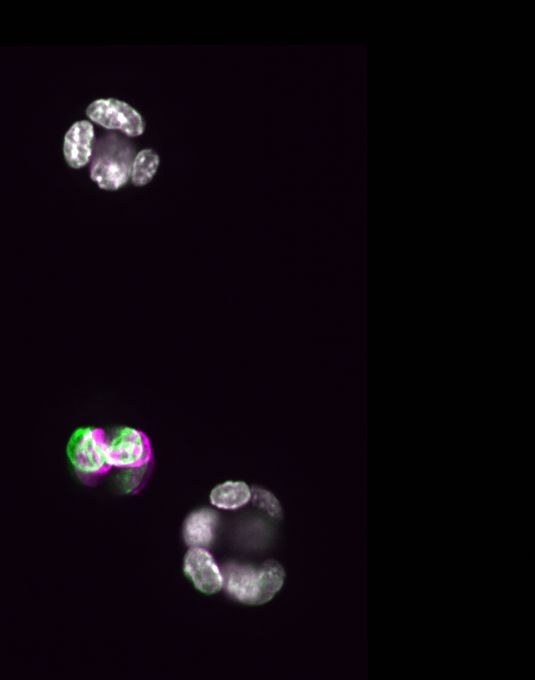

In [ ]:
show(fixed.data[25], moved.data[25])

"Before" is the same call with the identity: the moving image on the fixed grid, as the two sit in space. And since
the scene keeps the pyramids, the same transformation applies at every level: the whole organoid at the coarsest one,
in a moment.

In [ ]:
from ngff_zarr.v06.zarr_metadata import Identity

unmoved = nz.resample(Identity(input=T.input, output=T.output), fixed, moving)
print(f"correlation on one plane: {ncc(fixed.data[25], unmoved.data[25]):.2f} -> {ncc(fixed.data[25], moved.data[25]):.2f}")
coarse = nz.resample(T, scene.images["fixed"].images[2], scene.images["moving"].images[2], fields=scene_fields(SCENE, T))
print(f"at the coarsest level, {coarse.data.shape}: {ncc(scene.images['fixed'].images[2].data[12], coarse.data[12]):.2f}")

correlation on one plane: -0.06 -> 0.90
at the coarsest level, (50, 170, 133): 0.98


## The same transformation for the labels

The nuclei of each round, with an interpolation that keeps the labels. The score is the Dice of the two nuclei masks,
all nuclei together: how well they overlap, not whether each nucleus found its partner.

In [ ]:
nuclei_fixed = nz.from_ngff_zarr(f"{DATA}/fixed_nuclei.ome.zarr").images[0]
nuclei_moving = nz.from_ngff_zarr(f"{DATA}/moving_nuclei.ome.zarr").images[0]
carried = nz.resample(T, fixed, nuclei_moving, interpolator="label_image", fields=scene_fields(SCENE, T))
print(f"nuclei mask Dice: {dice(nuclei_fixed.data, nuclei_moving.data):.2f} -> {dice(nuclei_fixed.data, carried.data):.2f}")

nuclei mask Dice: 0.00 -> 0.92


## Map points

A landmark goes through the same transformation, with no image: a point of the fixed image, in micrometers and in
z, y, x order, comes out at its place in the moving image.

In [ ]:
!echo '[[15.0, 73.0, 58.0]]' > ../output/points.json
!ngff-zarr transform-points ../output/pair.ozx ../output/points.json

{"dims": ["z", "y", "x"], "points": [[16.362552751776104, 63.19099265213346, 94.37253238054313]]}


## See it in napari

napari shows `moved` as it is, still lazy: it computes only the plane on screen, for an affine or a field alike.
Scroll through the planes and zoom in to full resolution.

To open the scene in 3D Slicer instead, install the SlicerOMEZarr extension and drag `output/pair.ome.zarr` onto it.

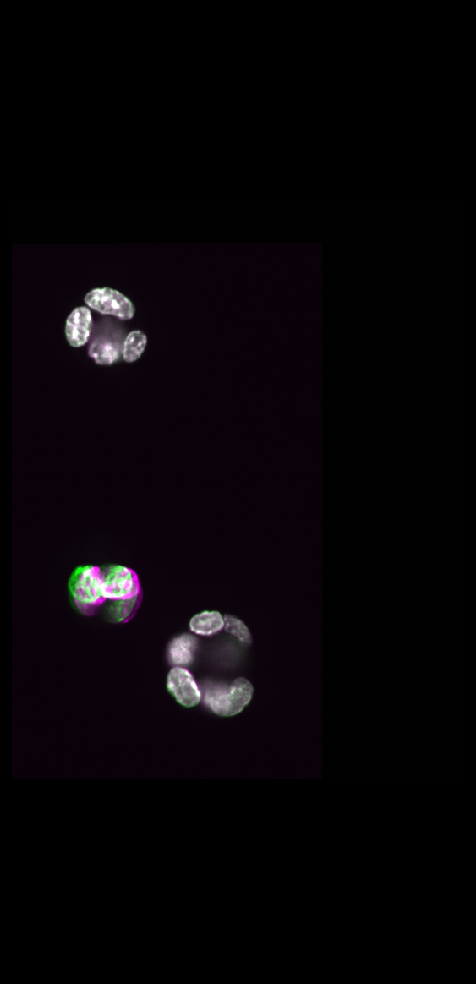

In [ ]:
from common import view
from napari.utils import nbscreenshot

viewer = view(fixed, moved)
viewer.window.resize(560, 500); viewer.reset_view()
nbscreenshot(viewer, canvas_only=True)

## You are done

You started from two images of a public plate. You now have one file with both images and their registration, in the
form RFC-5 gives every OME-Zarr reader: ngff-zarr applies it, napari and 3D Slicer show it.

**[Going further](../going-further.md):** your own images, 2-D images, larger images.